# 04 · Mối quan hệ giữa các biến nhiều chiều

Tương quan tuyến tính và thứ hạng, phụ thuộc đuôi, cấu trúc nhân tố (PCA), quan hệ dẫn–trễ,
và quan hệ khối lượng–biến động, cho **60 mã** (10 ngành; mã sắp theo ngành, nhãn tô màu theo ngành,
vạch đen phân cách ngành trên các heatmap). Ma trận đầy đủ 60×60 gồm 1.770 cặp không có hướng / 3.540 cặp có hướng;
heatmap cỡ này không ghi số trong ô — giá trị cụ thể ở bảng `report/table/eda/04_*`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.4f}".format)
con = U.connect()
SYMBOLS = U.SYMBOLS
COL = U.SYMBOL_COLORS
from scipy import stats
import statsmodels.api as sm
from scipy.stats import rankdata
from statsmodels.stats.multitest import multipletests

SECTOR, SECTORS, SC = U.SECTOR, U.SECTORS, U.SECTOR_COLORS


def sector_style(ax, labels, axis="both", sep=True, fs=9):
    """Tô màu nhãn trục theo ngành và kẻ vạch phân cách ngành trên heatmap (nhãn theo thứ tự U.SYMBOLS)."""
    ticks = range(len(labels))
    if axis in ("both", "x"):
        ax.set_xticks(ticks, labels, rotation=90, fontsize=fs)
        for t, s in zip(ax.get_xticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if axis in ("both", "y"):
        ax.set_yticks(ticks, labels, fontsize=fs)
        for t, s in zip(ax.get_yticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if sep:
        cuts = [i - 0.5 for i in range(1, len(labels)) if SECTOR[labels[i]] != SECTOR[labels[i - 1]]]
        for c in cuts:
            ax.axhline(c, color="black", lw=0.8); ax.axvline(c, color="black", lw=0.8)


def big_heatmap(ax, matrix, fs_cell=6.5, annotate=True, **kw):
    """Heatmap 20x20: chữ trong ô nhỏ (hoặc bỏ), nhãn tô màu theo ngành, vạch phân cách ngành."""
    im = U.make_heatmap(ax, matrix, **kw)
    for t in list(ax.texts):
        if annotate: t.set_fontsize(fs_cell)
        else: t.remove()
    sector_style(ax, list(matrix.index))
    return im


def sector_legend(ax_or_fig, **kw):
    from matplotlib.patches import Patch
    h = [Patch(color=SC[s], label=s) for s in SECTORS]
    return ax_or_fig.legend(handles=h, **kw)

In [2]:
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS].dropna()
print(r.shape)
pairs = [(a, b) for i, a in enumerate(SYMBOLS) for b in SYMBOLS[i + 1:]]          # 1.770 cặp không có hướng
pair_names = [f"{a}-{b}" for a, b in pairs]
same_sector = np.array([SECTOR[a] == SECTOR[b] for a, b in pairs])
print(f"{len(pairs)} cặp: {same_sector.sum()} cặp cùng ngành, {(~same_sector).sum()} cặp khác ngành")

(2103, 60)
1770 cặp: 235 cặp cùng ngành, 1535 cặp khác ngành


## 1. Ma trận tương quan: Pearson, Spearman, Kendall

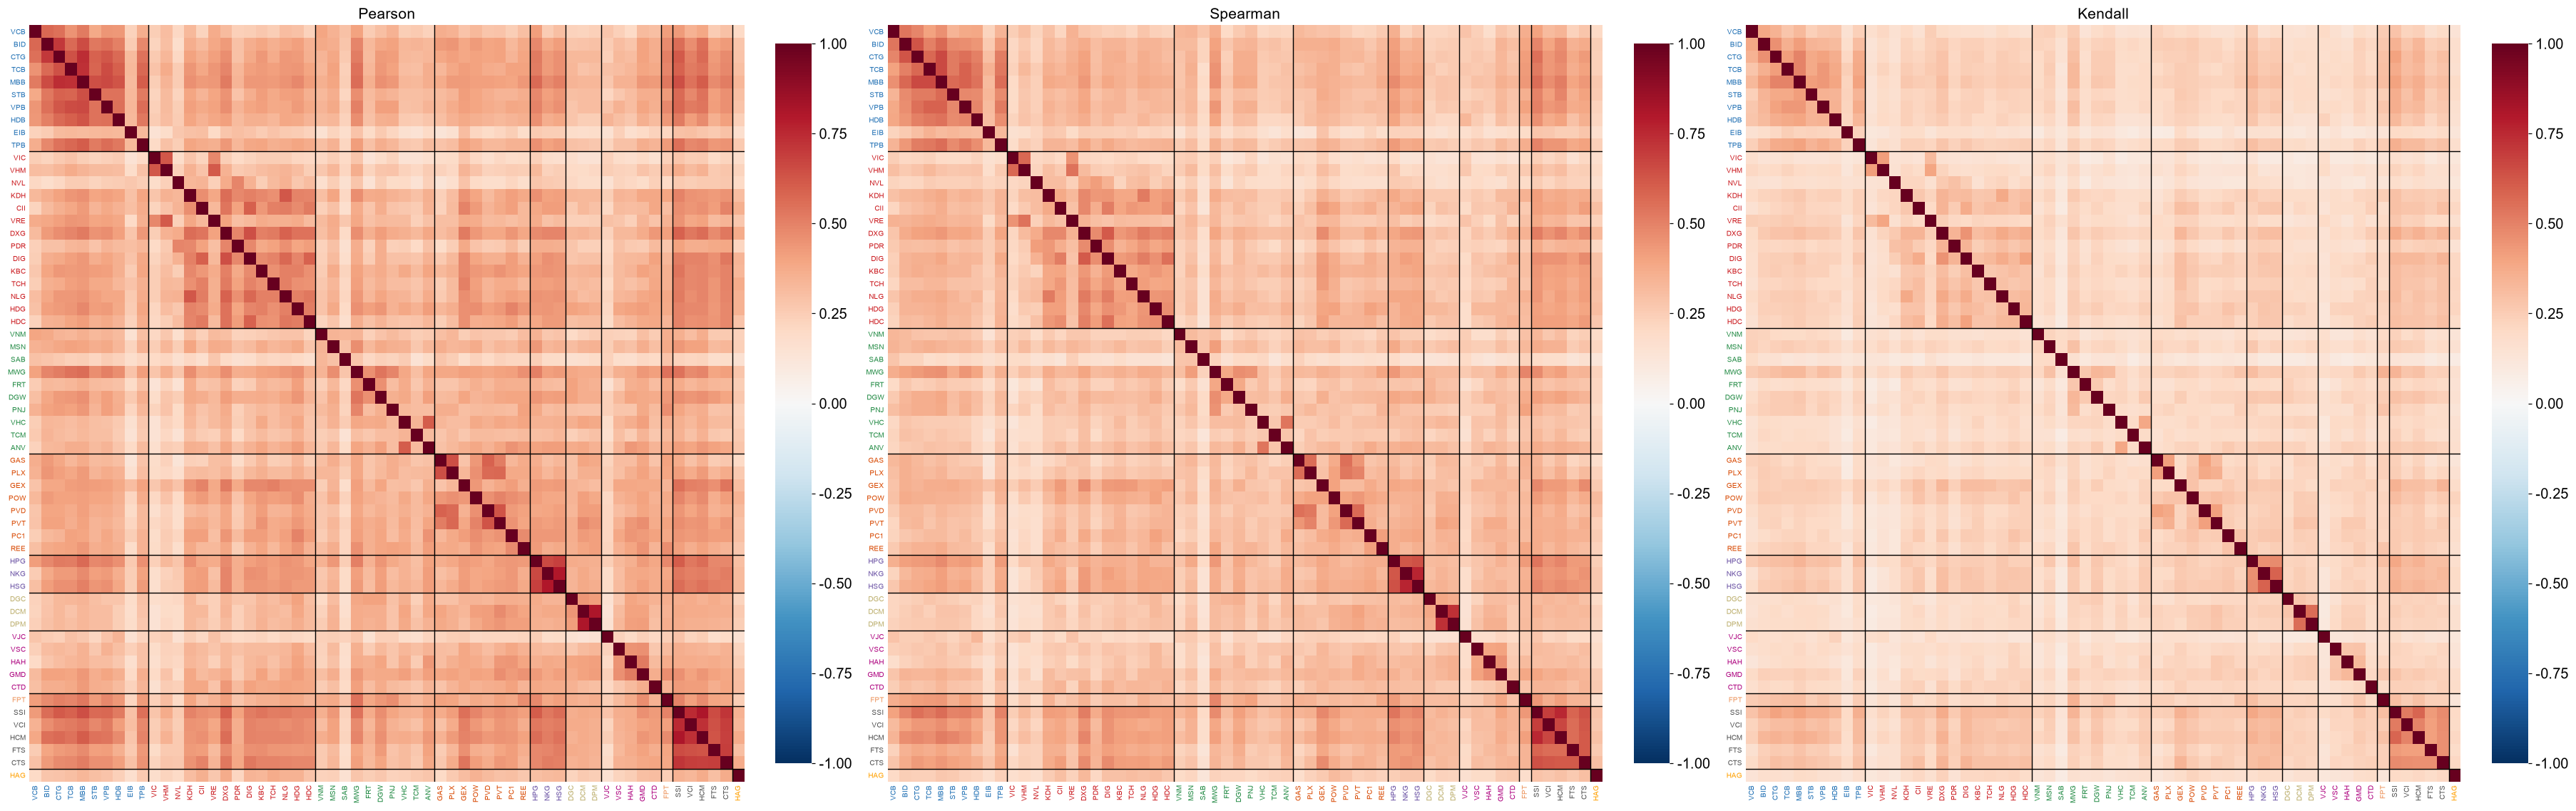

Tương quan 1770 cặp (min / trung vị / trung bình / max):
        pearson  spearman  kendall
min      0.1270    0.1150   0.0790
median   0.3510    0.3010   0.2090
mean     0.3550    0.3070   0.2150
max      0.8120    0.7610   0.5860

Cao nhất: {'SSI-CTS': 0.715, 'TCB-MBB': 0.73, 'VCI-HCM': 0.731, 'CTG-MBB': 0.742, 'SSI-VCI': 0.746, 'NKG-HSG': 0.801, 'DCM-DPM': 0.807, 'SSI-HCM': 0.812}
Thấp nhất: {'EIB-GAS': 0.127, 'NVL-GAS': 0.127, 'VIC-FRT': 0.133, 'DCM-VJC': 0.135, 'NVL-FRT': 0.141, 'VIC-VHC': 0.141, 'EIB-TCM': 0.141, 'NVL-TCM': 0.144}


In [3]:
corrs = {m: r.corr(method=m) for m in ("pearson", "spearman", "kendall")}
fig, axes = plt.subplots(1, 3, figsize=(33, 10.5))
for ax, (m, c) in zip(axes, corrs.items()):
    big_heatmap(ax, c, annotate=False, cmap="RdBu_r", vmin=-1, vmax=1, title=m.capitalize())
    sector_style(ax, SYMBOLS, fs=6.5)
U.finalize_figure(fig, "04_correlation_heatmaps")
plt.show()
for m, c in corrs.items():
    U.save_table(c, f"04_corr_{m}")

iu = np.triu_indices(len(SYMBOLS), 1)
off = pd.DataFrame({m: c.values[iu] for m, c in corrs.items()}, index=pair_names)
print(f"Tương quan {len(pairs)} cặp (min / trung vị / trung bình / max):")
print(off.agg(["min", "median", "mean", "max"]).round(3))
srt = off["pearson"].sort_values()
print("\nCao nhất:", srt.tail(8).round(3).to_dict())
print("Thấp nhất:", srt.head(8).round(3).to_dict())

**Tương quan theo ngành.** Trung bình Pearson giữa các mã của từng cặp ngành (đường chéo = trung bình các cặp trong cùng ngành; ngành chỉ có 1 mã để trống).

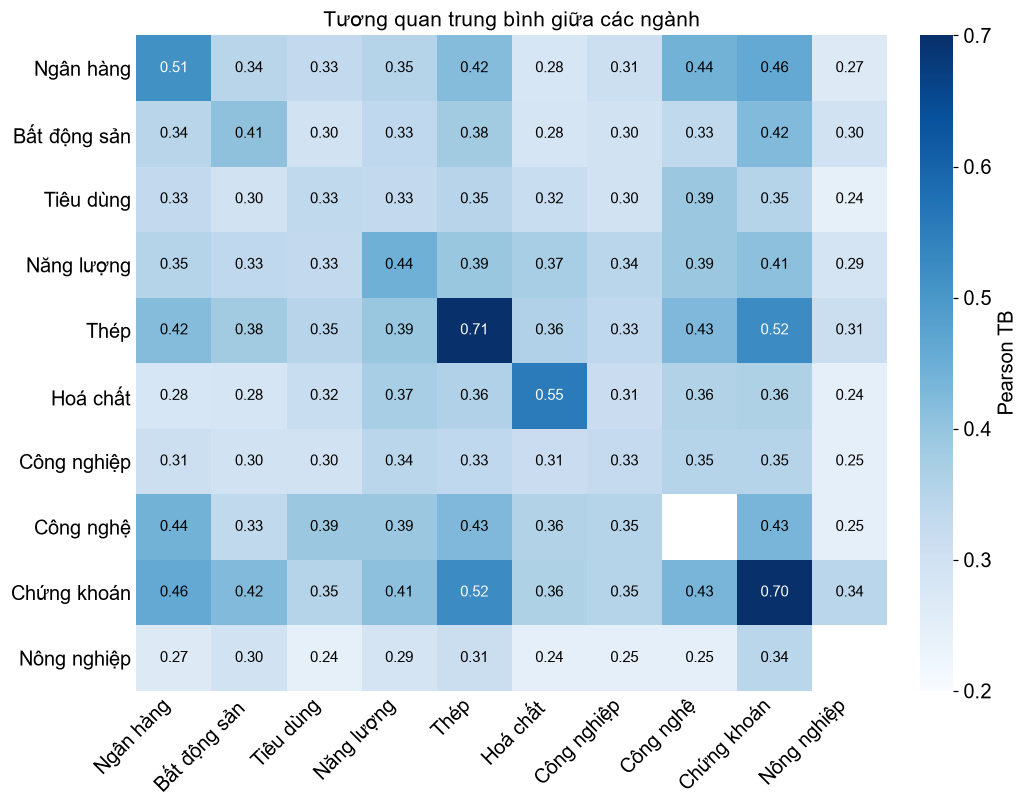

Pearson trung bình: cùng ngành 0.432 | khác ngành 0.343


,Ngân hàng,Bất động sản,Tiêu dùng,Năng lượng,Thép,Hoá chất,Công nghiệp,Công nghệ,Chứng khoán,Nông nghiệp
Ngân hàng,0.5100,0.3400,0.3300,0.3500,0.4200,0.2800,0.3100,0.4400,0.4600,0.2700
Bất động sản,0.3400,0.4100,0.3000,0.3300,0.3800,0.2800,0.3000,0.3300,0.4200,0.3000
Tiêu dùng,0.3300,0.3000,0.3300,0.3300,0.3500,0.3200,0.3000,0.3900,0.3500,0.2400
Năng lượng,0.3500,0.3300,0.3300,0.4400,0.3900,0.3700,0.3400,0.3900,0.4100,0.2900
Thép,0.4200,0.3800,0.3500,0.3900,0.7100,0.3600,0.3300,0.4300,0.5200,0.3100
Hoá chất,0.2800,0.2800,0.3200,0.3700,0.3600,0.5500,0.3100,0.3600,0.3600,0.2400
Công nghiệp,0.3100,0.3000,0.3000,0.3400,0.3300,0.3100,0.3300,0.3500,0.3500,0.2500
Công nghệ,0.4400,0.3300,0.3900,0.3900,0.4300,0.3600,0.3500,NaN,0.4300,0.2500
Chứng khoán,0.4600,0.4200,0.3500,0.4100,0.5200,0.3600,0.3500,0.4300,0.7000,0.3400
Nông nghiệp,0.2700,0.3000,0.2400,0.2900,0.3100,0.2400,0.2500,0.2500,0.3400,NaN


In [4]:
C = corrs["pearson"]
sec_corr = pd.DataFrame(np.nan, index=SECTORS, columns=SECTORS)
for sa in SECTORS:
    for sb in SECTORS:
        ma, mb = [s for s in SYMBOLS if SECTOR[s] == sa], [s for s in SYMBOLS if SECTOR[s] == sb]
        blk = C.loc[ma, mb].values
        if sa == sb:
            if len(ma) > 1: sec_corr.loc[sa, sb] = blk[np.triu_indices(len(ma), 1)].mean()
        else:
            sec_corr.loc[sa, sb] = blk.mean()
U.save_table(sec_corr, "04_corr_by_sector")
fig, ax = plt.subplots(figsize=(9.5, 7.5))
U.make_heatmap(ax, sec_corr, cmap="Blues", vmin=0.2, vmax=0.7, cbar_label="Pearson TB", title="Tương quan trung bình giữa các ngành")
ax.set_xticks(range(len(SECTORS)), SECTORS, rotation=45, ha="right")
U.finalize_figure(fig, "04_corr_by_sector")
plt.show()
within_mean = C.values[iu][same_sector].mean(); between_mean = C.values[iu][~same_sector].mean()
print(f"Pearson trung bình: cùng ngành {within_mean:.3f} | khác ngành {between_mean:.3f}")
sec_corr.round(2)

## 2. Ma trận phân tán (scatter matrix) của lợi suất — 5 mã gốc

Ma trận phân tán 60×60 (3.600 ô) không đọc được nên chỉ vẽ cho 5 mã gốc (VHM, NVL, STB, VPB, HPG); toàn bộ 60 mã được thể hiện bằng heatmap tương quan ở mục 1.

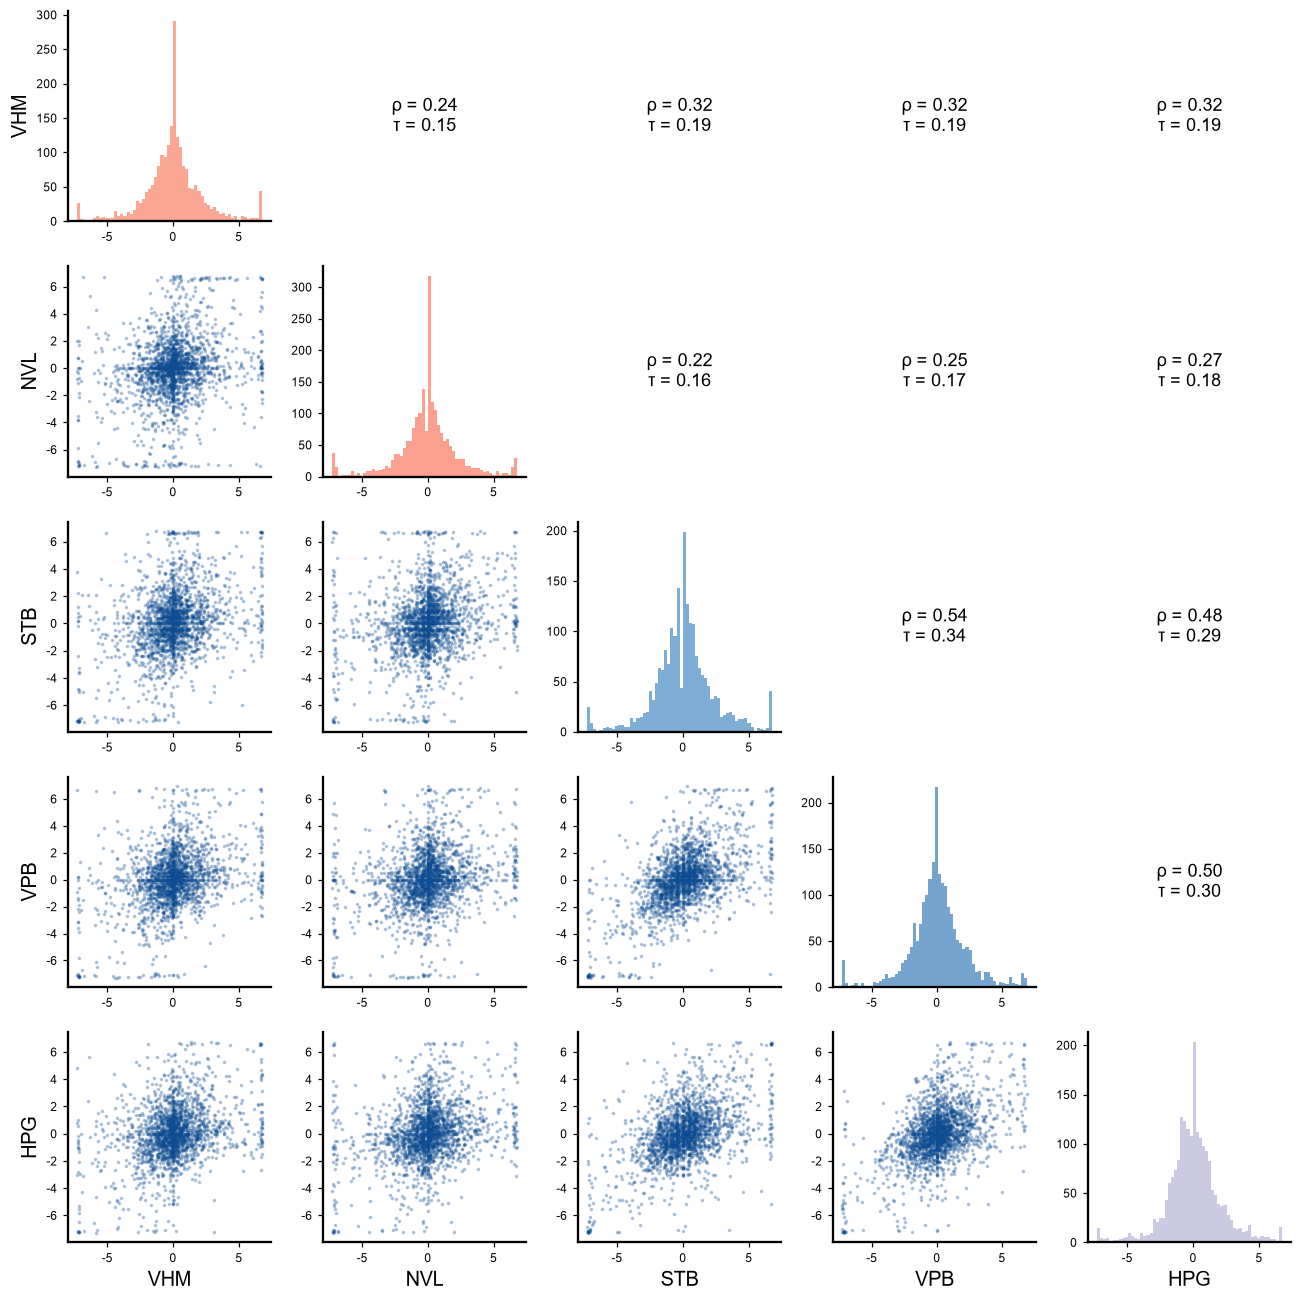

In [5]:
ORIG = U.ORIGINAL_SYMBOLS      # scatter matrix 60×60 không đọc được: vẽ cho 5 mã gốc; toàn bộ 60 mã xem heatmap ở mục 1
n = len(ORIG)
fig, axes = plt.subplots(n, n, figsize=(12, 12))
for i, a in enumerate(ORIG):
    for j, b in enumerate(ORIG):
        ax = axes[i, j]
        if i == j:
            ax.hist(100 * r[a], bins=60, color=COL[a], alpha=0.6)
        elif i > j:
            ax.scatter(100 * r[b], 100 * r[a], s=2, alpha=0.25, color=U.PALETTE["blue_main"])
        else:
            ax.text(0.5, 0.5, f"ρ = {corrs['pearson'].loc[a, b]:.2f}\nτ = {corrs['kendall'].loc[a, b]:.2f}",
                    ha="center", va="center", transform=ax.transAxes, fontsize=12)
            ax.set_axis_off()
        if j == 0: ax.set_ylabel(a)
        if i == n - 1: ax.set_xlabel(b)
        ax.tick_params(labelsize=8)
U.finalize_figure(fig, "04_scatter_matrix")
plt.show()

## 3. Tương quan động (cửa sổ trượt 120 phiên)

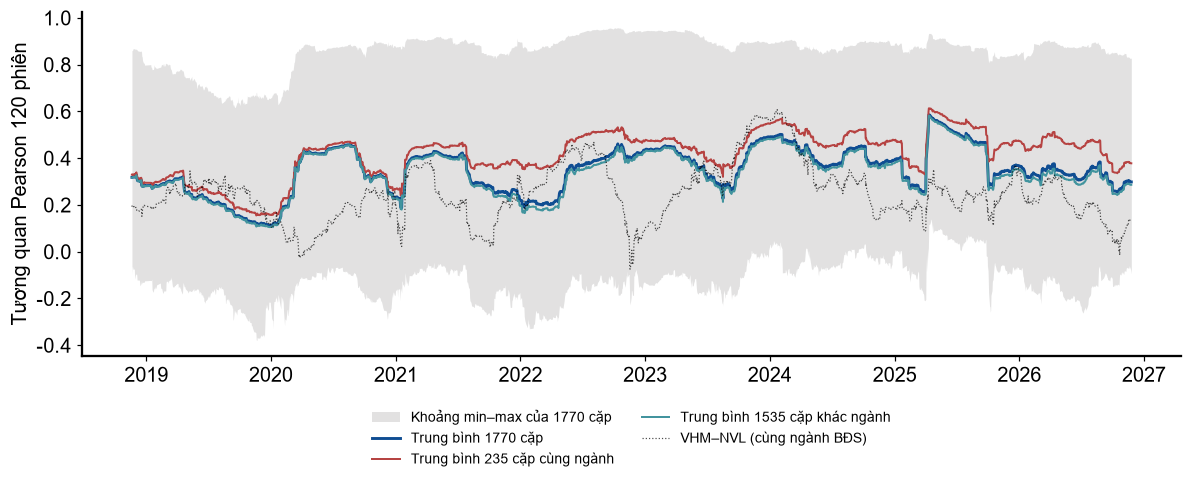

Tương quan trung bình 1770 cặp: min 0.11 (07/01/2020), max 0.59 (11/04/2025), cả kỳ 0.35
Cùng ngành 0.42 | khác ngành 0.34 | khoảng cách trung bình 0.08
Trung bình theo năm: {2018: 0.31, 2019: 0.21, 2020: 0.34, 2021: 0.33, 2022: 0.34, 2023: 0.39, 2024: 0.42, 2025: 0.41, 2026: 0.33}


In [6]:
W = 120
roll = pd.DataFrame({k: r[a].rolling(W).corr(r[b]) for k, (a, b) in zip(pair_names, pairs)})
avg_corr = roll.mean(axis=1)
within = roll.loc[:, same_sector].mean(axis=1)       # trung bình các cặp cùng ngành
between = roll.loc[:, ~same_sector].mean(axis=1)     # trung bình các cặp khác ngành

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.fill_between(roll.index, roll.min(axis=1), roll.max(axis=1), color=U.PALETTE["neutral"], alpha=0.6,
                lw=0, label=f"Khoảng min–max của {len(pairs)} cặp")
ax.plot(avg_corr.index, avg_corr, color=U.PALETTE["blue_main"], lw=1.9, label=f"Trung bình {len(pairs)} cặp")
ax.plot(within.index, within, color=U.PALETTE["red_strong"], lw=1.3, label=f"Trung bình {same_sector.sum()} cặp cùng ngành")
ax.plot(between.index, between, color=U.PALETTE["teal"], lw=1.3, label=f"Trung bình {(~same_sector).sum()} cặp khác ngành")
ax.plot(roll.index, roll["VHM-NVL"], color="black", lw=0.8, alpha=0.7, ls=":", label="VHM–NVL (cùng ngành BĐS)")
ax.set_ylabel(f"Tương quan Pearson {W} phiên")
ax.legend(fontsize=9, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
U.finalize_figure(fig, "04_rolling_correlation")
plt.show()
print(f"Tương quan trung bình {len(pairs)} cặp: min {avg_corr.min():.2f} ({avg_corr.idxmin():%d/%m/%Y}), max {avg_corr.max():.2f} ({avg_corr.idxmax():%d/%m/%Y}), cả kỳ {avg_corr.mean():.2f}")
print(f"Cùng ngành {within.mean():.2f} | khác ngành {between.mean():.2f} | khoảng cách trung bình {(within - between).mean():.2f}")
print("Trung bình theo năm:", avg_corr.groupby(avg_corr.index.year).mean().round(2).to_dict())

## 4. Tương quan trong giai đoạn căng thẳng và bình thường

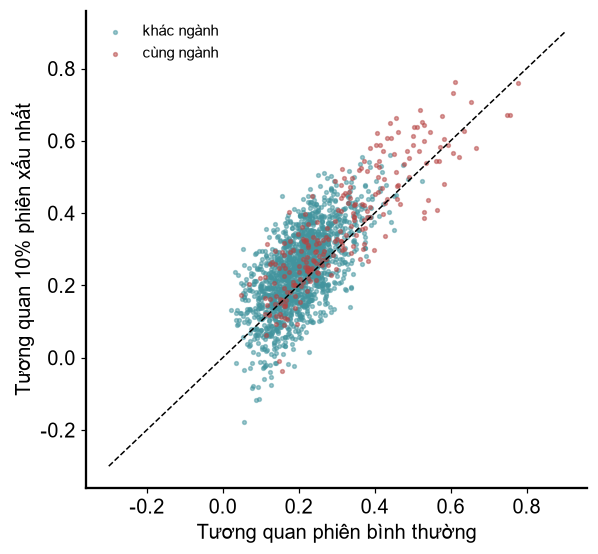

Số phiên căng thẳng: 211
Trung bình tương quan: bình thường 0.218 -> căng thẳng 0.257
Số cặp có tương quan GIẢM khi căng thẳng: 549 / 1770
Trung bình thay đổi: cùng ngành 0.046 | khác ngành 0.038


,bình thường (90% còn lại),căng thẳng (10% phiên xấu nhất),cùng ngành,thay đổi
NVL-GAS,0.0558,-0.1771,False,-0.2329
FRT-FTS,0.2279,0.0146,False,-0.2133
NVL-PVD,0.0965,-0.1147,False,-0.2112
VCB-CTS,0.1871,-0.0235,False,-0.2106
DPM-HAH,0.2671,0.5118,False,0.2447
TCM-VJC,0.0541,0.3007,False,0.2466
DGC-HAH,0.2521,0.5047,False,0.2526
SAB-FPT,0.1566,0.4484,False,0.2918


In [7]:
mkt = r.mean(axis=1)                                   # danh mục đều các mã làm đại diện "thị trường"
stress = mkt <= mkt.quantile(0.10)
calm_c, stress_c = r[~stress].corr(), r[stress].corr()
cmp_ = pd.DataFrame({
    "bình thường (90% còn lại)": calm_c.values[iu],
    "căng thẳng (10% phiên xấu nhất)": stress_c.values[iu],
    "cùng ngành": same_sector,
}, index=pair_names)
cmp_["thay đổi"] = cmp_.iloc[:, 1] - cmp_.iloc[:, 0]
U.save_table(cmp_, "04_corr_stress_vs_calm")

fig, ax = plt.subplots(figsize=(5.6, 5.2))
for flag, col, lab in [(False, U.PALETTE["teal"], "khác ngành"), (True, U.PALETTE["red_strong"], "cùng ngành")]:
    d = cmp_[cmp_["cùng ngành"] == flag]
    ax.scatter(d.iloc[:, 0], d.iloc[:, 1], s=6, alpha=0.5, color=col, label=lab)
ax.plot([-0.3, 0.9], [-0.3, 0.9], color="black", lw=1, ls="--")
ax.set_xlabel("Tương quan phiên bình thường"); ax.set_ylabel("Tương quan 10% phiên xấu nhất")
ax.legend(fontsize=10)
U.finalize_figure(fig, "04_corr_stress_vs_calm")
plt.show()
print(f"Số phiên căng thẳng: {int(stress.sum())}")
print("Trung bình tương quan: bình thường %.3f -> căng thẳng %.3f" % (cmp_.iloc[:, 0].mean(), cmp_.iloc[:, 1].mean()))
print("Số cặp có tương quan GIẢM khi căng thẳng: %d / %d" % ((cmp_["thay đổi"] < 0).sum(), len(cmp_)))
print("Trung bình thay đổi: cùng ngành %.3f | khác ngành %.3f" % (cmp_.loc[cmp_["cùng ngành"], "thay đổi"].mean(), cmp_.loc[~cmp_["cùng ngành"], "thay đổi"].mean()))
cmp_.sort_values("thay đổi").iloc[[0, 1, 2, 3, -4, -3, -2, -1]]

## 5. Phụ thuộc đuôi dưới thực nghiệm

$\hat\lambda_L(q) = \dfrac{\#\{U_{1t}\le q,\ U_{2t}\le q\}}{n\,q}$ với $U$ là hạng chuẩn hoá. So với
giá trị kỳ vọng nếu phụ thuộc là chuẩn (Gaussian copula) cùng hệ số tương quan.

Sai số nội suy λ_Gauss lớn nhất trên 1770 cặp: 1.58e-05


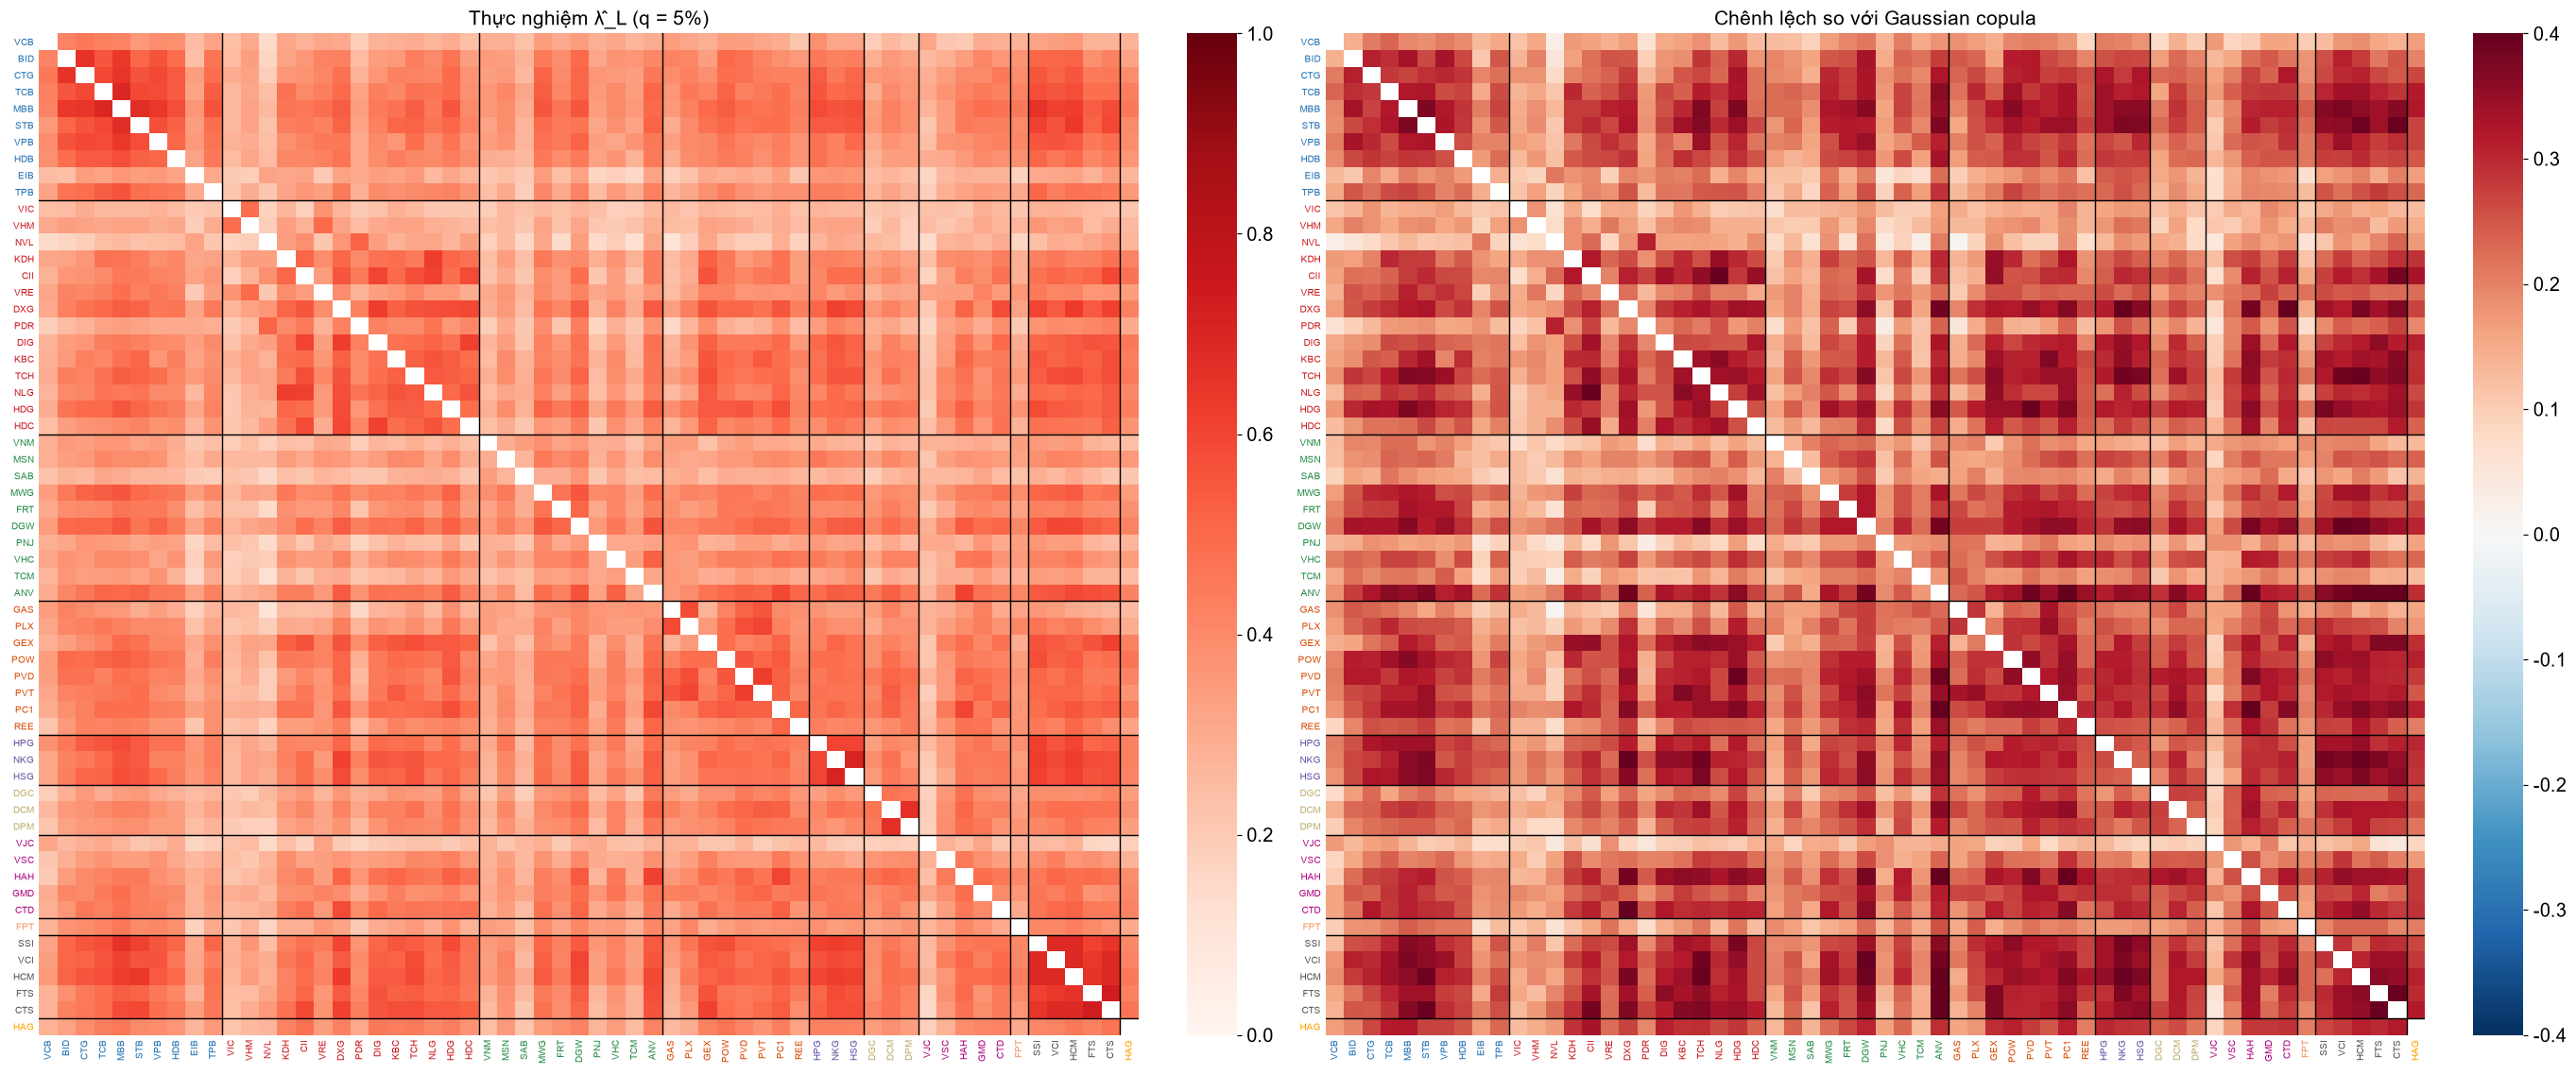

WindowsPath('D:/2026.1/Đồ án II/report/table/eda/04_lower_tail_dependence.csv')

In [8]:
Q = 0.05
zq = stats.norm.ppf(Q)
# λ_Gauss chỉ phụ thuộc ρ -> tính sẵn trên lưới ρ rồi nội suy (nhanh hơn nhiều khi bootstrap 1.770 cặp × 1.000 lần)
RH = np.linspace(-0.95, 0.99, 300)
LG = np.array([stats.multivariate_normal([0, 0], [[1, p], [p, 1]]).cdf([zq, zq]) for p in RH]) / Q

def tail_mats(x):
    """x: mảng n×p lợi suất. Trả về (λ̂_L thực nghiệm, λ_Gauss) dạng ma trận p×p."""
    n = len(x)
    ranks = rankdata(x, axis=0)
    ind = (ranks / (n + 1) <= Q).astype(float)
    lam = ind.T @ ind / (n * Q)
    rho = 2 * np.sin(np.pi / 6 * np.corrcoef(ranks.T))      # ρ Pearson suy từ ρ Spearman (Gaussian copula)
    return lam, np.interp(rho, RH, LG)

lam_emp, lam_g = tail_mats(r.values)
lamL = pd.DataFrame(lam_emp, index=SYMBOLS, columns=SYMBOLS).mask(np.eye(len(SYMBOLS), dtype=bool))
lamG = pd.DataFrame(lam_g, index=SYMBOLS, columns=SYMBOLS).mask(np.eye(len(SYMBOLS), dtype=bool))

# kiểm tra sai số nội suy so với công thức chính xác (mvn.cdf) trên mọi cặp
rho_s = 2 * np.sin(np.pi / 6 * corrs["spearman"].values[iu])
exact = np.array([stats.multivariate_normal([0, 0], [[1, p], [p, 1]]).cdf([zq, zq]) / Q for p in rho_s])
print(f"Sai số nội suy λ_Gauss lớn nhất trên {len(pairs)} cặp: {np.abs(exact - lam_g[iu]).max():.2e}")

fig, axes = plt.subplots(1, 2, figsize=(25, 10.5))
big_heatmap(axes[0], lamL, annotate=False, cmap="Reds", vmin=0, vmax=1, title=f"Thực nghiệm λ̂_L (q = {Q:.0%})")
big_heatmap(axes[1], lamL - lamG, annotate=False, cmap="RdBu_r", vmin=-0.4, vmax=0.4,
            title="Chênh lệch so với Gaussian copula")
for ax in axes: sector_style(ax, SYMBOLS, fs=6.5)
U.finalize_figure(fig, "04_lower_tail_dependence")
plt.show()
U.save_table(lamL, "04_lower_tail_dependence")

**Độ bất định:** mỗi λ̂_L chỉ dựa trên vài chục phiên đồng thời rơi vào đuôi, nên ước lượng khoảng tin
cậy 95% cho chênh lệch $\hat\lambda_L - \lambda_{Gauss}$ bằng **bootstrap khối** (khối 20 phiên, 1.000 lần)
để giữ cấu trúc biến động cụm.

In [9]:
rng = np.random.default_rng(42)
B, BLOCK, n = 1000, 20, len(r)
rv = r.values
starts_all = np.arange(n - BLOCK + 1)
diff_obs = (lam_emp - lam_g)[iu]
boot = np.empty((B, len(pairs)))
for b in range(B):
    starts = rng.choice(starts_all, size=int(np.ceil(n / BLOCK)))
    idx = (starts[:, None] + np.arange(BLOCK)).ravel()[:n]
    lb, gb = tail_mats(rv[idx])
    boot[b] = (lb - gb)[iu]
tail_ci = pd.DataFrame({
    "λ̂_L": lam_emp[iu],
    "λ_Gauss": lam_g[iu],
    "λ̂_L − λ_Gauss": diff_obs,
    "CI 2,5%": np.percentile(boot, 2.5, axis=0),
    "CI 97,5%": np.percentile(boot, 97.5, axis=0),
    "cùng ngành": same_sector,
}, index=pair_names)
tail_ci["CI loại trừ 0"] = tail_ci["CI 2,5%"] > 0
U.save_table(tail_ci, "04_tail_dependence_bootstrap")
print(f"B = {B} lần, khối {BLOCK} phiên; CI 95% từng cặp (chưa hiệu chỉnh đa kiểm định).")
print(f"λ̂_L: trung bình {tail_ci['λ̂_L'].mean():.3f} (độc lập = {Q}); λ_Gauss trung bình {tail_ci['λ_Gauss'].mean():.3f}")
print("Chênh lệch λ̂_L − λ_Gauss: min %.3f | trung bình %.3f | max %.3f" % tuple(tail_ci["λ̂_L − λ_Gauss"].agg(["min", "mean", "max"])))
print(f"Cặp có CI loại trừ 0: {int(tail_ci['CI loại trừ 0'].sum())}/{len(tail_ci)}; cặp có chênh lệch > 0: {(tail_ci['λ̂_L − λ_Gauss'] > 0).sum()}")
for flag, lab in [(True, "cùng ngành"), (False, "khác ngành")]:
    d = tail_ci[tail_ci["cùng ngành"] == flag]
    print(f"{lab}: λ̂_L TB {d['λ̂_L'].mean():.3f} | λ_Gauss TB {d['λ_Gauss'].mean():.3f} | chênh lệch TB {d['λ̂_L − λ_Gauss'].mean():.3f} | CI>0: {int(d['CI loại trừ 0'].sum())}/{len(d)}")
tail_ci.sort_values("λ̂_L", ascending=False).head(10)

B = 1000 lần, khối 20 phiên; CI 95% từng cặp (chưa hiệu chỉnh đa kiểm định).
λ̂_L: trung bình 0.387 (độc lập = 0.05); λ_Gauss trung bình 0.155
Chênh lệch λ̂_L − λ_Gauss: min 0.011 | trung bình 0.233 | max 0.443
Cặp có CI loại trừ 0: 1746/1770; cặp có chênh lệch > 0: 1770
cùng ngành: λ̂_L TB 0.433 | λ_Gauss TB 0.196 | chênh lệch TB 0.236 | CI>0: 233/235
khác ngành: λ̂_L TB 0.380 | λ_Gauss TB 0.148 | chênh lệch TB 0.232 | CI>0: 1513/1535


,λ̂_L,λ_Gauss,λ̂_L − λ_Gauss,"CI 2,5%","CI 97,5%",cùng ngành,CI loại trừ 0
FTS-CTS,0.7323,0.3355,0.3968,0.2789,0.4499,True,True
NKG-HSG,0.7038,0.4681,0.2357,0.1471,0.3082,True,True
TCB-MBB,0.6942,0.3746,0.3197,0.2285,0.3841,True,True
SSI-VCI,0.6847,0.3972,0.2875,0.1994,0.3519,True,True
SSI-HCM,0.6847,0.4644,0.2203,0.1571,0.3163,True,True
VCI-CTS,0.6847,0.3422,0.3426,0.2488,0.4086,True,True
VCI-HCM,0.6847,0.3794,0.3054,0.2336,0.3810,True,True
HCM-CTS,0.6847,0.3347,0.3501,0.2378,0.4196,True,True
MBB-STB,0.6752,0.3009,0.3743,0.2713,0.4365,True,True
DCM-DPM,0.6657,0.4342,0.2315,0.1482,0.3328,True,True


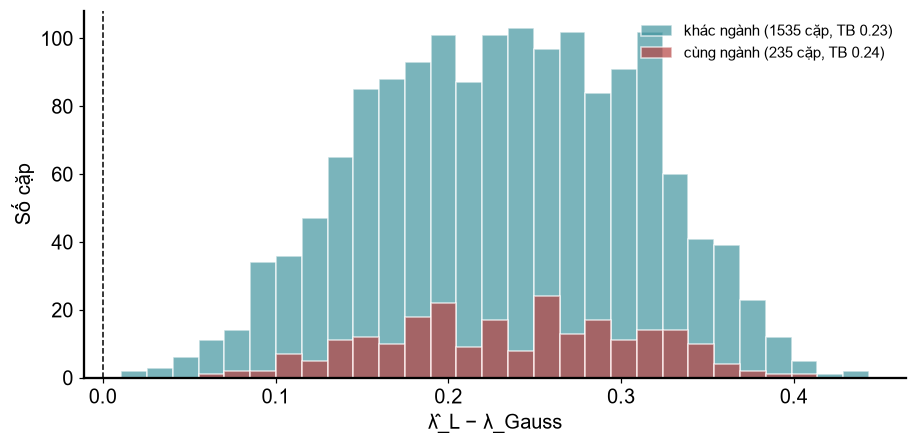

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bins = np.linspace(tail_ci["λ̂_L − λ_Gauss"].min(), tail_ci["λ̂_L − λ_Gauss"].max(), 30)
for flag, col, lab in [(False, U.PALETTE["teal"], "khác ngành"), (True, U.PALETTE["red_strong"], "cùng ngành")]:
    d = tail_ci[tail_ci["cùng ngành"] == flag]["λ̂_L − λ_Gauss"]
    ax.hist(d, bins=bins, alpha=0.7, color=col, edgecolor="white", label=f"{lab} ({len(d)} cặp, TB {d.mean():.2f})")
ax.axvline(0, color="black", lw=1, ls="--")
ax.set_xlabel("λ̂_L − λ_Gauss"); ax.set_ylabel("Số cặp"); ax.legend(fontsize=10)
U.finalize_figure(fig, "04_lower_tail_dependence_dist")
plt.show()

## 6. Phân tích thành phần chính (PCA)

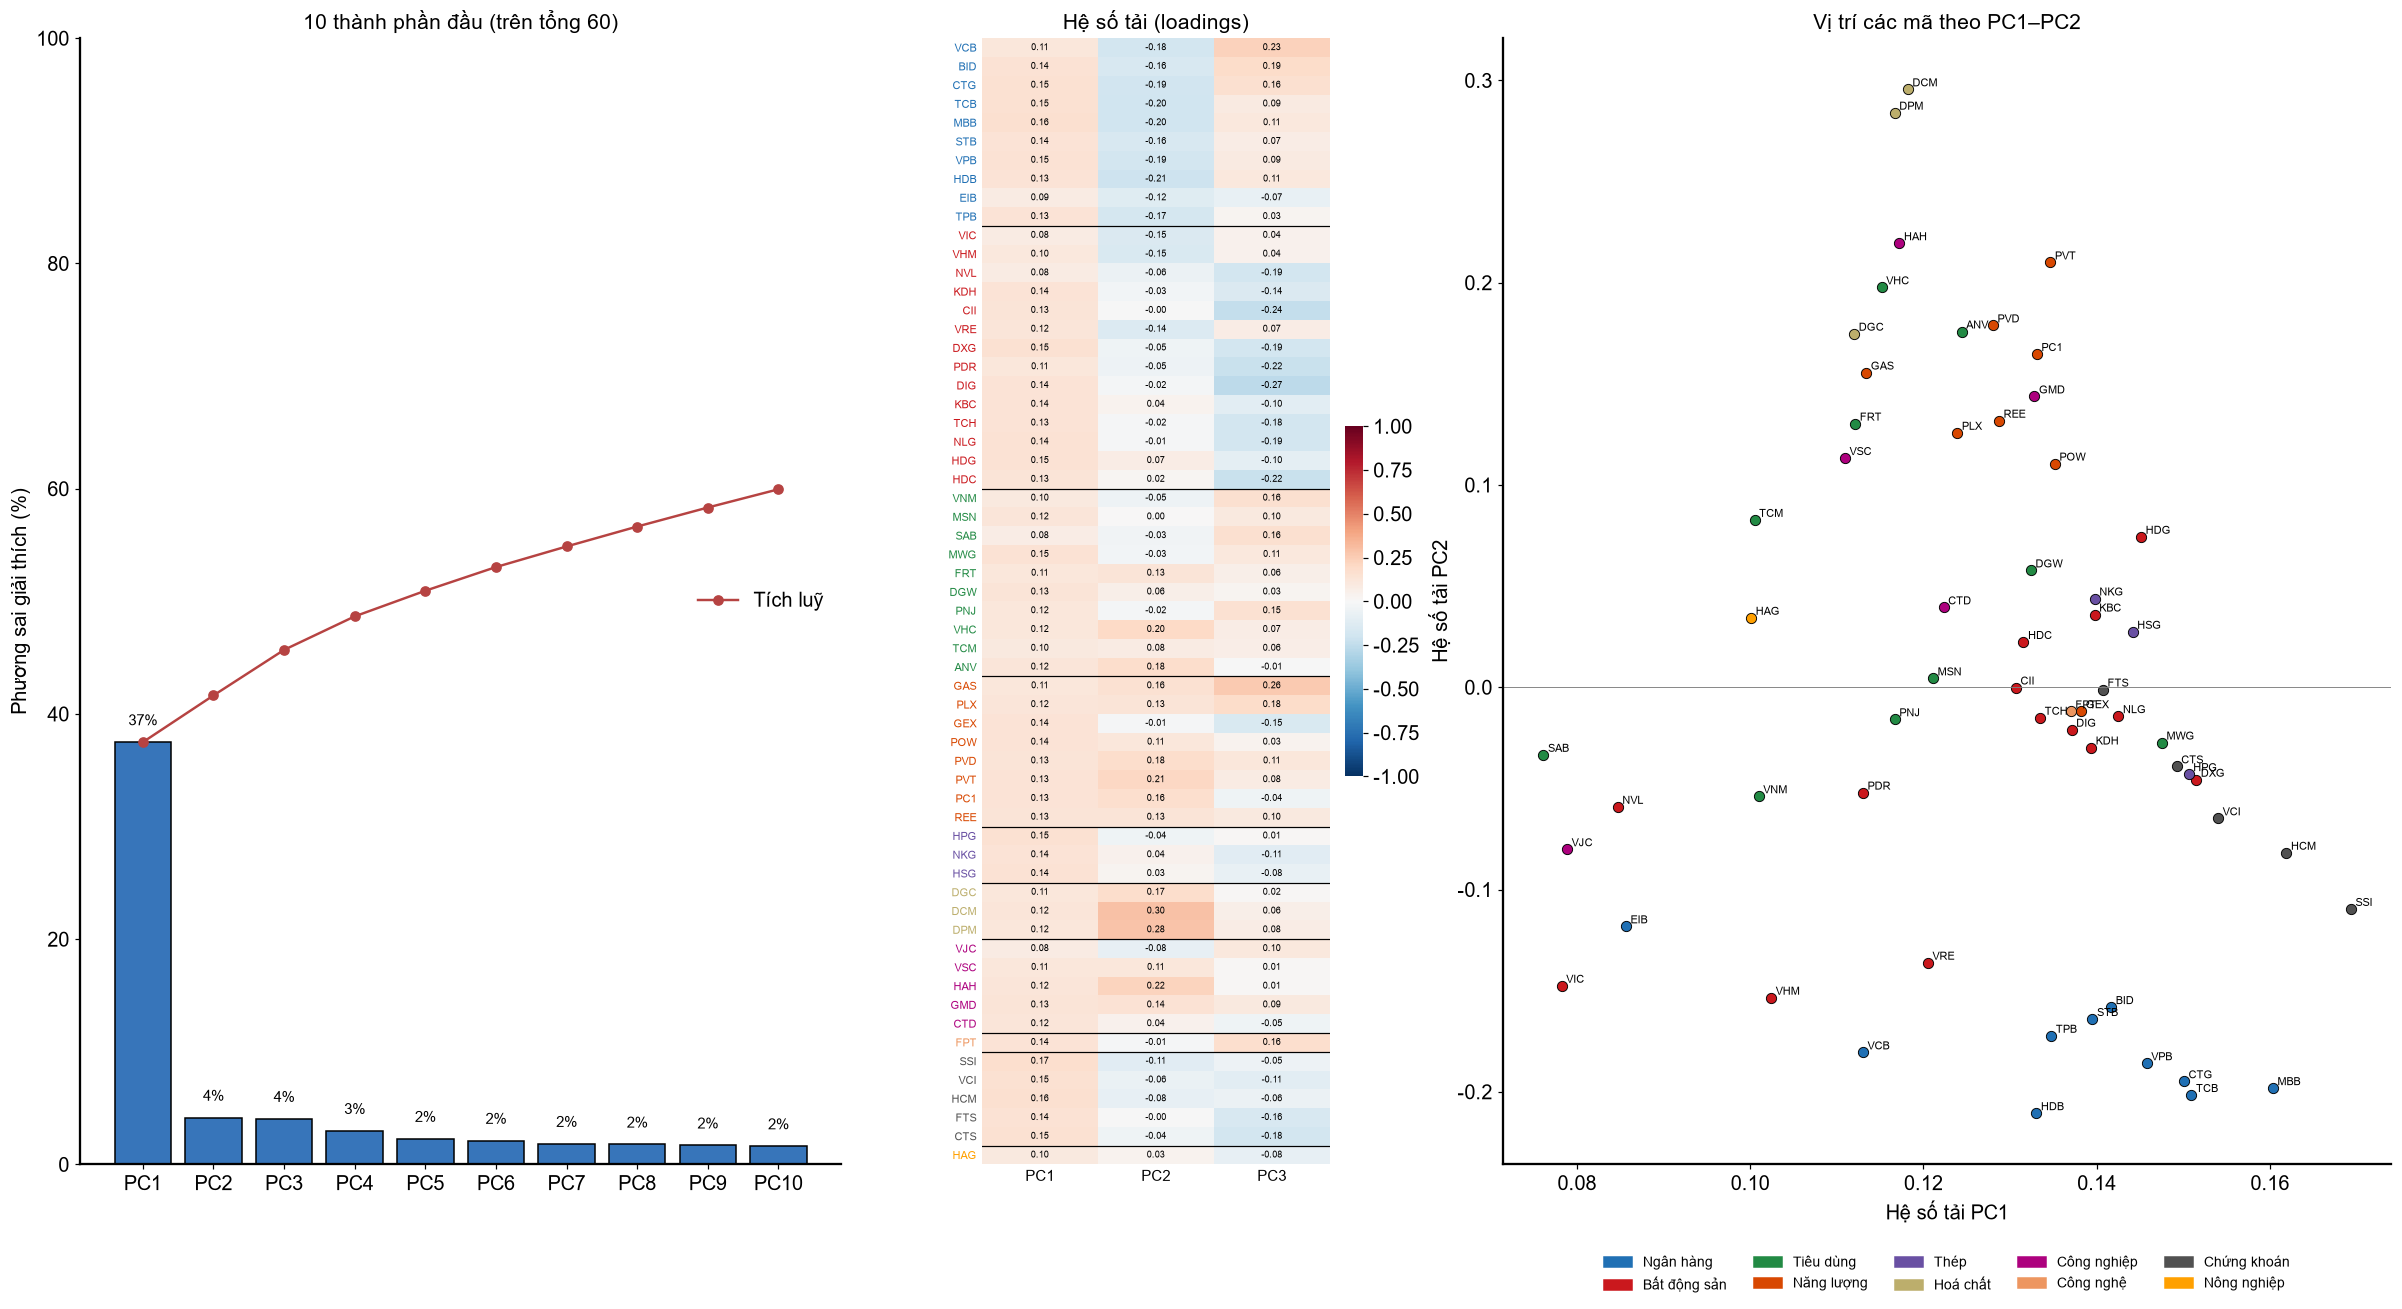

Phương sai giải thích PC1–PC6 (%): [37.5, 4.2, 4.0, 3.0, 2.3, 2.1]
Số PC để đạt 50% / 70% / 80%: 5 / 18 / 28
Ngưỡng Marchenko–Pastur λ_max = 1.37; số trị riêng vượt ngưỡng: 4; λ1 = 22.50
PC1: tải nhỏ nhất / lớn nhất: SAB 0.08 / SSI 0.17
PC1 trung bình theo ngành: {'Ngân hàng': 0.14, 'Bất động sản': 0.12, 'Tiêu dùng': 0.11, 'Năng lượng': 0.13, 'Thép': 0.14, 'Hoá chất': 0.12, 'Công nghiệp': 0.11, 'Công nghệ': 0.14, 'Chứng khoán': 0.16, 'Nông nghiệp': 0.1}
PC2 tải lớn nhất: {'DCM': 0.3, 'DPM': 0.28, 'HAH': 0.22, 'HDB': -0.21}
PC3 tải lớn nhất: {'DIG': -0.27, 'GAS': 0.26, 'CII': -0.24, 'VCB': 0.23}
PC4 tải lớn nhất: {'VIC': 0.42, 'VHM': 0.4, 'VRE': 0.3, 'NVL': 0.21}


,PC1,PC2,PC3,PC4,PC5,PC6
tỷ lệ giải thích,0.3749,0.0415,0.0405,0.0297,0.0228,0.0210


In [11]:
Z = (r - r.mean()) / r.std()
eigval, eigvec = np.linalg.eigh(Z.cov().values)
order = eigval.argsort()[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
eigvec = eigvec * np.sign(eigvec.sum(axis=0))            # cố định dấu cho dễ đọc
explained = eigval / eigval.sum()
loadings = pd.DataFrame(eigvec, index=SYMBOLS, columns=[f"PC{i+1}" for i in range(len(SYMBOLS))])
mp_max = (1 + np.sqrt(len(SYMBOLS) / len(r))) ** 2       # ngưỡng Marchenko–Pastur: trị riêng của nhiễu thuần tuý

fig, axes = plt.subplots(1, 3, figsize=(22, 12), gridspec_kw={"width_ratios": [1.2, 0.6, 1.4]})
K = 10
pcs = loadings.columns[:K]
axes[0].bar(pcs, 100 * explained[:K], color=U.PALETTE["blue_secondary"], edgecolor="black", lw=1)
axes[0].plot(pcs, 100 * explained.cumsum()[:K], color=U.PALETTE["red_strong"], marker="o", lw=1.6, label="Tích luỹ")
for i, v in enumerate(explained[:K]):
    axes[0].text(i, 100 * v + 1.5, f"{100*v:.0f}%", ha="center", fontsize=10)
axes[0].set_ylabel("Phương sai giải thích (%)"); axes[0].set_ylim(0, 100)
axes[0].set_title(f"{K} thành phần đầu (trên tổng {len(SYMBOLS)})")
axes[0].legend(loc="center right")
U.make_heatmap(axes[1], loadings[["PC1", "PC2", "PC3"]], vmin=-1, vmax=1, title="Hệ số tải (loadings)")
for t in axes[1].texts: t.set_fontsize(6)
sector_style(axes[1], SYMBOLS, axis="y", sep=False, fs=7)
axes[1].set_xticks(range(3), ["PC1", "PC2", "PC3"], rotation=0, fontsize=10)
for i in range(1, len(SYMBOLS)):
    if SECTOR[SYMBOLS[i]] != SECTOR[SYMBOLS[i - 1]]: axes[1].axhline(i - 0.5, color="black", lw=0.8)
for s in SYMBOLS:
    axes[2].scatter(loadings.loc[s, "PC1"], loadings.loc[s, "PC2"], s=45, color=SC[SECTOR[s]], edgecolor="black", lw=0.6)
    axes[2].annotate(s, (loadings.loc[s, "PC1"], loadings.loc[s, "PC2"]), xytext=(3, 2), textcoords="offset points", fontsize=7.5)
axes[2].axhline(0, color="gray", lw=0.6); axes[2].set_xlabel("Hệ số tải PC1"); axes[2].set_ylabel("Hệ số tải PC2")
axes[2].set_title("Vị trí các mã theo PC1–PC2")
sector_legend(axes[2], loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=5, fontsize=9)
U.finalize_figure(fig, "04_pca")
plt.show()
U.save_table(pd.concat([loadings, pd.DataFrame([explained], index=["explained"], columns=loadings.columns)]),
             "04_pca_loadings")
print("Phương sai giải thích PC1–PC6 (%):", (100 * explained[:6]).round(1).tolist())
print(f"Số PC để đạt 50% / 70% / 80%: {int(np.argmax(explained.cumsum() >= .5)) + 1} / {int(np.argmax(explained.cumsum() >= .7)) + 1} / {int(np.argmax(explained.cumsum() >= .8)) + 1}")
print(f"Ngưỡng Marchenko–Pastur λ_max = {mp_max:.2f}; số trị riêng vượt ngưỡng: {(eigval > mp_max).sum()}; λ1 = {eigval[0]:.2f}")
print("PC1: tải nhỏ nhất / lớn nhất:", loadings["PC1"].idxmin(), round(loadings["PC1"].min(), 2), "/", loadings["PC1"].idxmax(), round(loadings["PC1"].max(), 2))
print("PC1 trung bình theo ngành:", loadings["PC1"].groupby(lambda s: SECTOR[s], sort=False).mean().round(2).to_dict())
for pc in ("PC2", "PC3", "PC4"):
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(pc, "tải lớn nhất:", {s: round(float(loadings.loc[s, pc]), 2) for s in top})
pd.Series(explained, index=loadings.columns, name="tỷ lệ giải thích").head(6).to_frame().T

## 7. Quan hệ dẫn–trễ: kiểm định nhân quả Granger (sai số chuẩn HAC)

Với mỗi cặp có hướng $a \to b$, ước lượng một hồi quy với **số lag cố định chọn trước** $p = 5$ (một tuần giao dịch):
$b_t = c + \sum_{i=1}^{p}\beta_i b_{t-i} + \sum_{i=1}^{p}\gamma_i a_{t-i} + \varepsilon_t$, rồi kiểm định Wald
$H_0: \gamma_1 = \dots = \gamma_p = 0$. Dùng sai số chuẩn **HAC (Newey–West)** vì notebook 03 cho thấy có ARCH,
nên F-test thông thường (giả định phương sai đồng nhất) không hợp lệ. Mỗi cặp đúng **một** kiểm định → 60 × 59 = **3.540 kiểm định**:
ngưỡng Bonferroni $0{,}05/3540 \approx 1{,}4\times10^{-5}$; đồng thời báo cáo hiệu chỉnh **Holm** (bớt bảo thủ hơn Bonferroni, vẫn kiểm soát FWER).
Với 3.540 kiểm định, nếu mọi $H_0$ đúng thì kỳ vọng khoảng $3540 \times 0{,}05 = 177$ cặp có $p < 0{,}05$ chỉ do ngẫu nhiên.

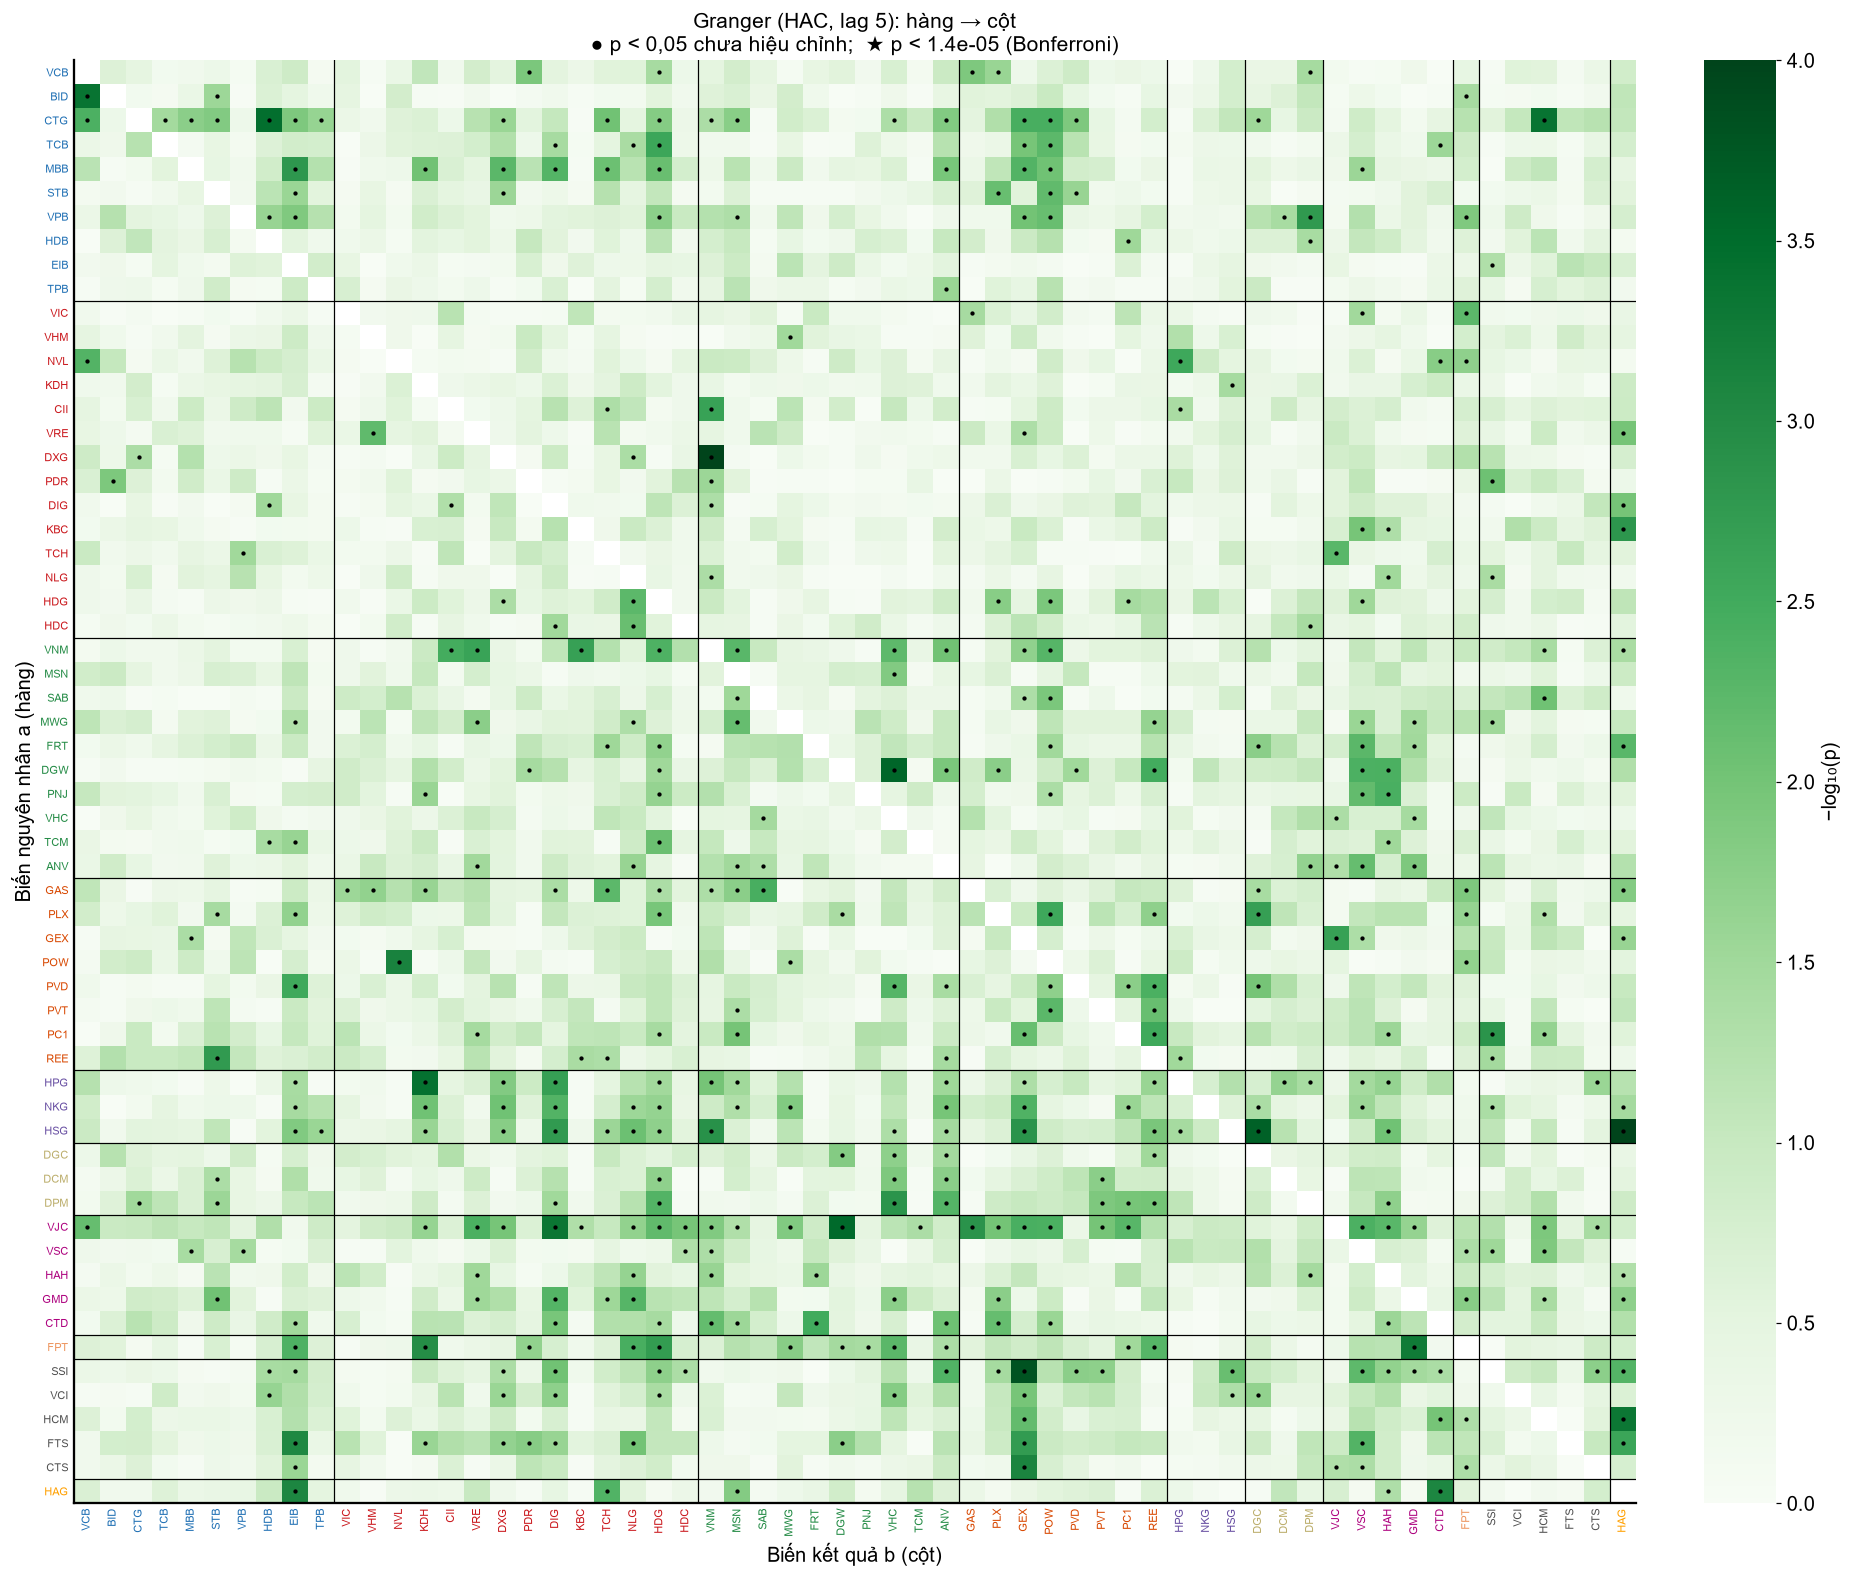

3540 kiểm định | p < 0,05: 402 (kỳ vọng ngẫu nhiên ≈ 177) | Bonferroni (p < 1.41e-05): 0 | Holm: 0
Theo nguyên nhân (số p < 0,05): {'VJC': 25, 'CTG': 19, 'SSI': 18, 'HSG': 17, 'HPG': 15}
Theo kết quả (số p < 0,05): {'HDG': 23, 'EIB': 17, 'GEX': 17, 'ANV': 16, 'VSC': 16}
Tỷ lệ p < 0,05: cùng ngành 0.100 | khác ngành 0.116
Tương quan trễ 1 phiên |ρ| lớn nhất: 0.155


,nguyên nhân,kết quả,Wald χ²,p (HAC),"corr(a_{t-1}, b_t)",p Holm,có ý nghĩa (Bonferroni),có ý nghĩa (Holm),cùng ngành
967,DXG,VNM,27.7760,0.0000,-0.0713,0.1425,False,False,False
2654,HSG,HAG,27.7538,0.0000,0.0845,0.1439,False,False,False
3222,SSI,GEX,24.7511,0.0002,0.1348,0.5506,False,False,False
2640,HSG,DGC,23.8380,0.0002,0.0580,0.8250,False,False,False
1741,DGW,VHC,23.4760,0.0003,0.1051,0.9677,False,False,True
2861,VJC,DGW,23.2421,0.0003,0.0407,1.0000,False,False,False
124,CTG,HDB,22.8433,0.0004,0.0742,1.0000,False,False,True
2491,HPG,KDH,22.6941,0.0004,0.1065,1.0000,False,False,False


In [12]:
LAG = 5
lagged = {s: pd.concat({f"{s}_l{i}": r[s].shift(i) for i in range(1, LAG + 1)}, axis=1) for s in SYMBOLS}
rows = []
for a in SYMBOLS:
    for b in SYMBOLS:
        if a == b: continue
        X = sm.add_constant(pd.concat([lagged[b], lagged[a]], axis=1)).dropna()
        y = r[b].loc[X.index]
        fit = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        wald = fit.wald_test(" = 0, ".join(lagged[a].columns) + " = 0", scalar=True)
        rows.append({"nguyên nhân": a, "kết quả": b, "Wald χ²": wald.statistic, "p (HAC)": wald.pvalue,
                     "corr(a_{t-1}, b_t)": r[a].shift(1).corr(r[b])})
granger = pd.DataFrame(rows)
BONF = 0.05 / len(granger)
granger["p Holm"] = multipletests(granger["p (HAC)"], method="holm")[1]
granger["có ý nghĩa (Bonferroni)"] = granger["p (HAC)"] < BONF
granger["có ý nghĩa (Holm)"] = granger["p Holm"] < 0.05
granger["cùng ngành"] = [SECTOR[a] == SECTOR[b] for a, b in zip(granger["nguyên nhân"], granger["kết quả"])]
U.save_table(granger.set_index(["nguyên nhân", "kết quả"]), "04_granger")
pmat = granger.pivot(index="nguyên nhân", columns="kết quả", values="p (HAC)").loc[SYMBOLS, SYMBOLS]
nlp = -np.log10(pmat)

fig, ax = plt.subplots(figsize=(17, 14.5))
im = ax.imshow(nlp.values, cmap="Greens", vmin=0, vmax=4, aspect="auto")
for i in range(len(SYMBOLS)):
    for j in range(len(SYMBOLS)):
        p = pmat.values[i, j]
        if np.isnan(p): continue
        if p < BONF: ax.plot(j, i, marker="*", ms=8, color=U.PALETTE["red_strong"], mec="black", mew=0.4)
        elif p < 0.05: ax.plot(j, i, marker="o", ms=1.8, color="black")
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("−log₁₀(p)"); cb.outline.set_visible(False)
ax.tick_params(length=0)
sector_style(ax, SYMBOLS, fs=7)
ax.set_xlabel("Biến kết quả b (cột)"); ax.set_ylabel("Biến nguyên nhân a (hàng)")
ax.set_title(f"Granger (HAC, lag {LAG}): hàng → cột\n● p < 0,05 chưa hiệu chỉnh;  ★ p < {BONF:.1e} (Bonferroni)")
U.finalize_figure(fig, "04_granger_pvalues")
plt.show()
nsig = int((granger["p (HAC)"] < 0.05).sum())
print(f"{len(granger)} kiểm định | p < 0,05: {nsig} (kỳ vọng ngẫu nhiên ≈ {0.05 * len(granger):.0f}) | Bonferroni (p < {BONF:.2e}): {int(granger['có ý nghĩa (Bonferroni)'].sum())} | Holm: {int(granger['có ý nghĩa (Holm)'].sum())}")
print("Theo nguyên nhân (số p < 0,05):", granger[granger["p (HAC)"] < .05]["nguyên nhân"].value_counts().head(5).to_dict())
print("Theo kết quả (số p < 0,05):", granger[granger["p (HAC)"] < .05]["kết quả"].value_counts().head(5).to_dict())
print("Tỷ lệ p < 0,05: cùng ngành %.3f | khác ngành %.3f" % tuple(granger.groupby("cùng ngành")["p (HAC)"].apply(lambda p: (p < .05).mean()).reindex([True, False])))
print("Tương quan trễ 1 phiên |ρ| lớn nhất: %.3f" % granger["corr(a_{t-1}, b_t)"].abs().max())
granger.sort_values("p (HAC)").head(8)

Lưu ý: Granger chỉ là **dự báo được** theo nghĩa tuyến tính, không phải nhân quả cấu trúc; nhân tố
thị trường chung (PC1) và biến động cụm vẫn có thể tạo quan hệ giả.

## 8. Quan hệ khối lượng – biến động

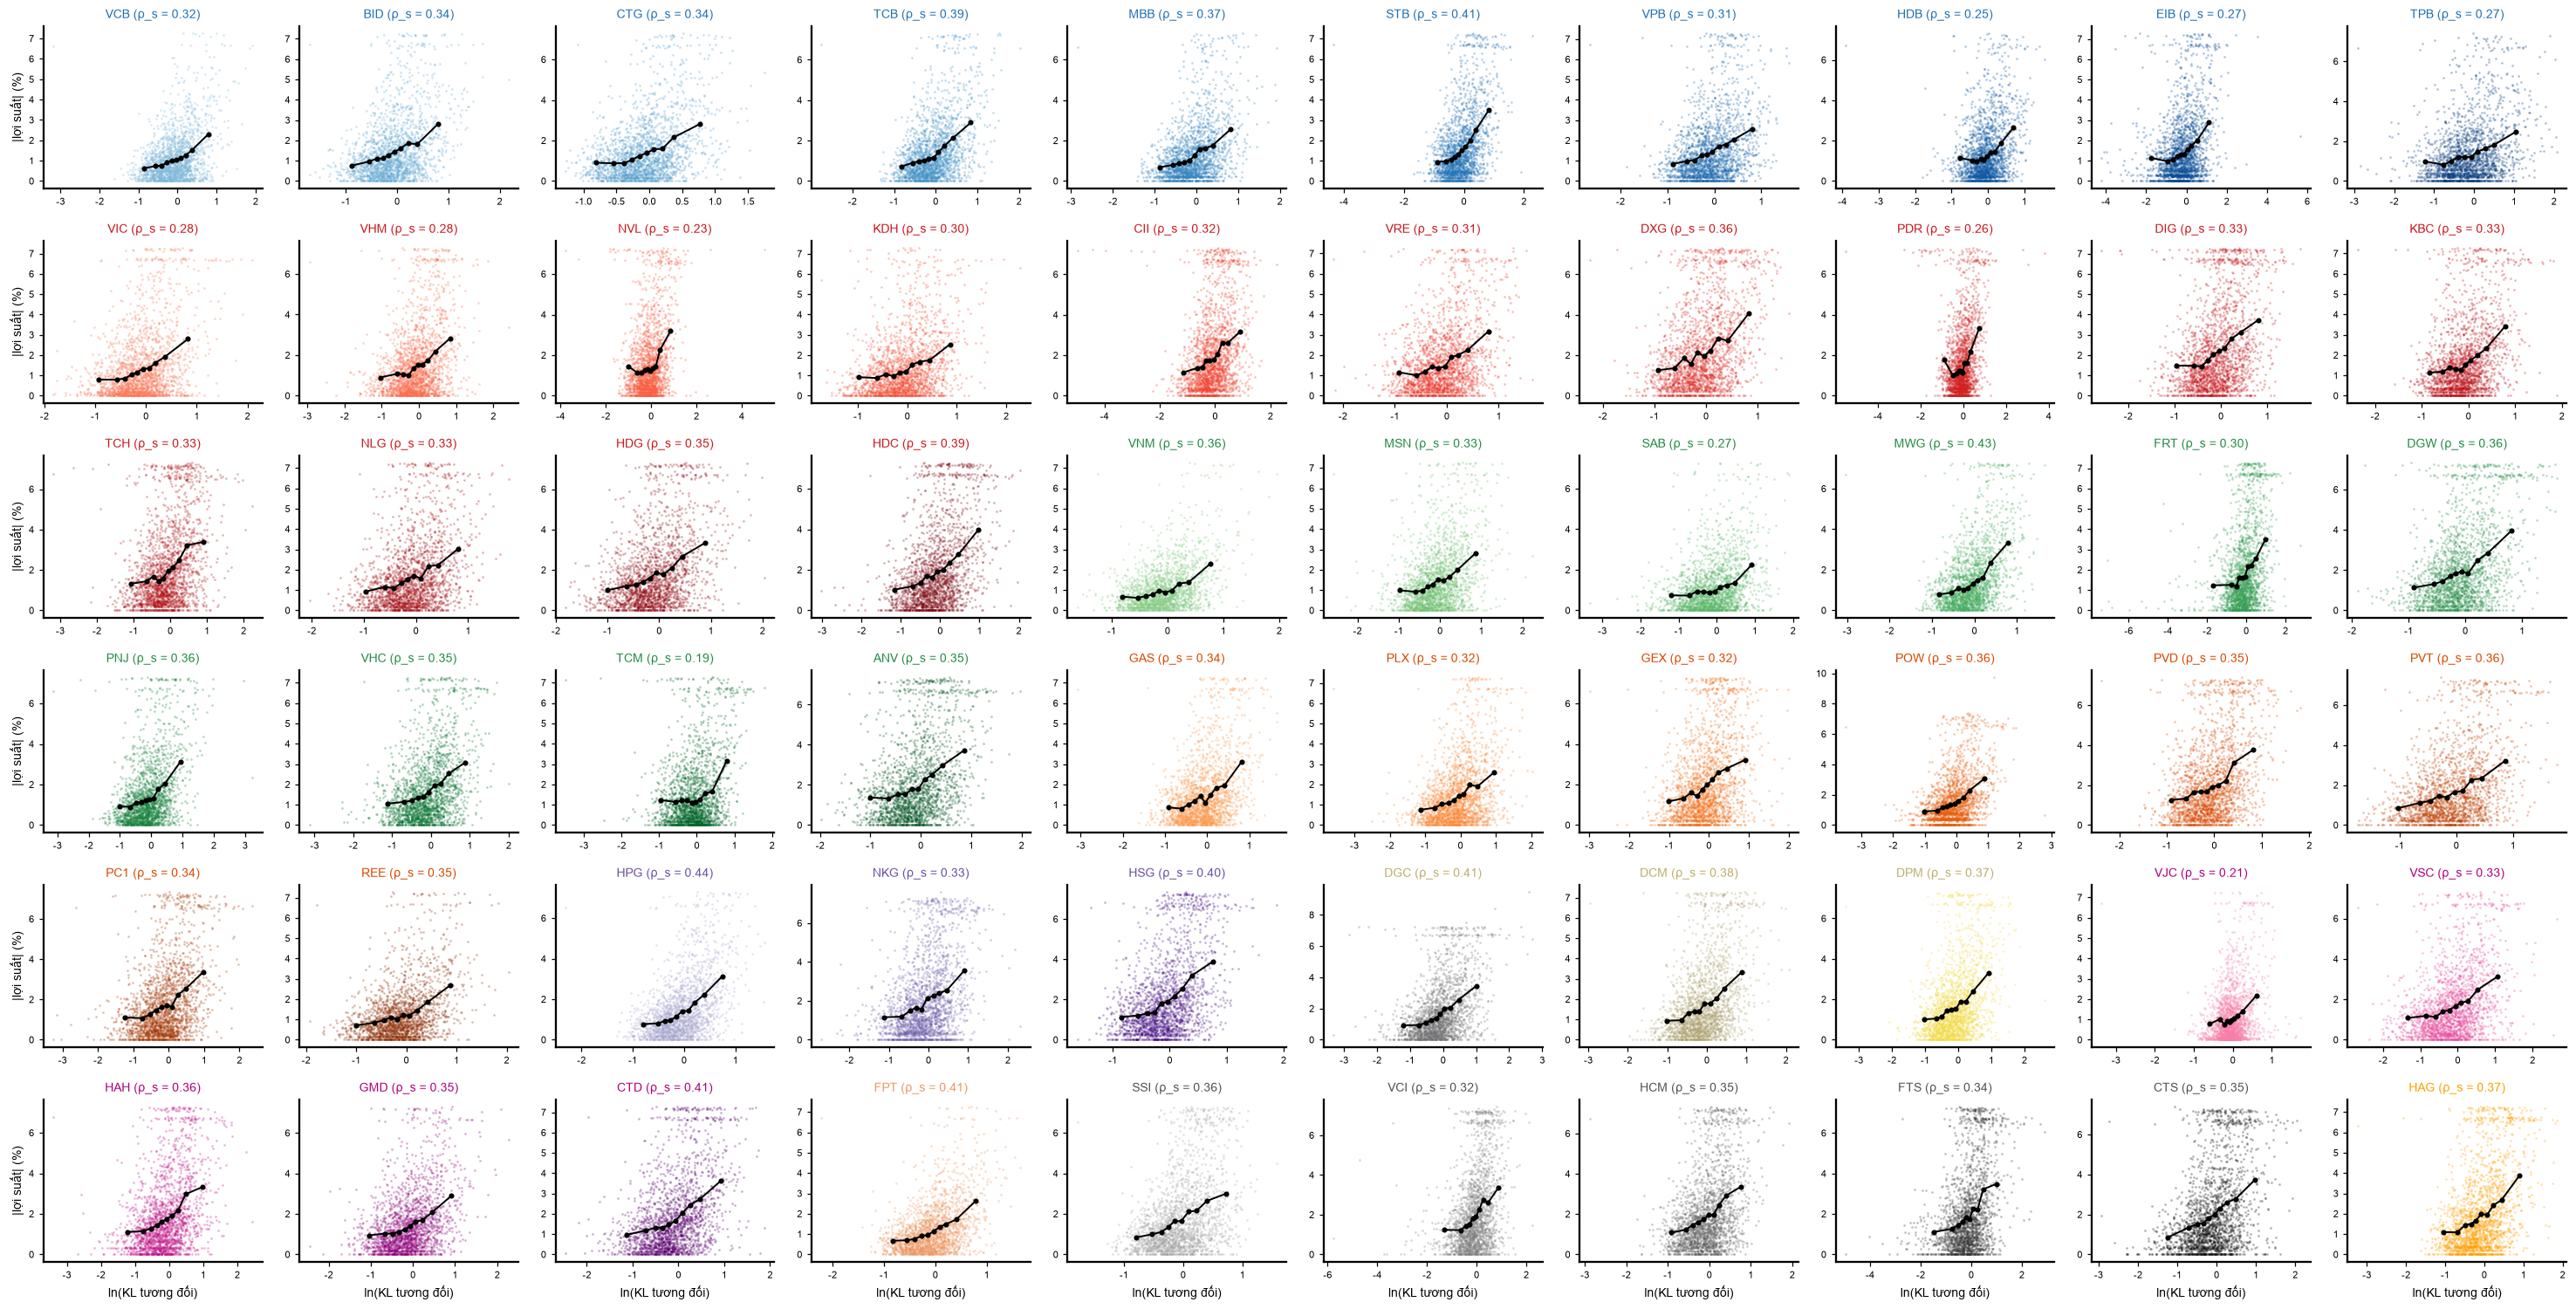

Spearman ρ: min 0.19 (TCM) | max 0.44 (HPG) | trung bình 0.34; số mã p < 0,001: 60/60
Trung bình theo ngành: {'Ngân hàng': 0.33, 'Bất động sản': 0.32, 'Tiêu dùng': 0.33, 'Năng lượng': 0.34, 'Thép': 0.39, 'Hoá chất': 0.39, 'Công nghiệp': 0.33, 'Công nghệ': 0.41, 'Chứng khoán': 0.35, 'Nông nghiệp': 0.37}


,ngành,Spearman ρ,p,|r| decile 1 (%),|r| decile 10 (%),tỷ số D10/D1
symbol,,,,,,
VCB,Ngân hàng,0.3157,0.0000,0.6247,2.3111,3.6996
BID,Ngân hàng,0.3429,0.0000,0.7585,2.8172,3.7144
CTG,Ngân hàng,0.3431,0.0000,0.9036,2.8061,3.1056
TCB,Ngân hàng,0.3878,0.0000,0.7192,2.8890,4.0172
MBB,Ngân hàng,0.3681,0.0000,0.6791,2.5585,3.7677
STB,Ngân hàng,0.4068,0.0000,0.9367,3.4798,3.7148
VPB,Ngân hàng,0.3111,0.0000,0.8462,2.5613,3.0267
HDB,Ngân hàng,0.2524,0.0000,1.1562,2.6467,2.2892
EIB,Ngân hàng,0.2722,0.0000,1.1456,2.8830,2.5166


In [13]:
vv = con.execute("""
    SELECT symbol, ABS(log_ret) AS abs_ret, LN(rel_volume) AS log_rel_vol
    FROM v_analysis WHERE rel_volume > 0""").df()
fig, axes = plt.subplots(*U.symbol_grid(), figsize=U.symbol_grid_size(2.7, 2.3))
rows = []
for ax, s in zip(axes.ravel(), SYMBOLS):
    d = vv[vv.symbol == s]
    ax.scatter(d.log_rel_vol, 100 * d.abs_ret, s=1, alpha=0.2, color=COL[s])
    bins = pd.qcut(d.log_rel_vol, 10)
    m = d.groupby(bins, observed=True).agg(x=("log_rel_vol", "mean"), y=("abs_ret", "mean"))
    ax.plot(m.x, 100 * m.y, color="black", marker="o", ms=3, lw=1.3)
    rho = stats.spearmanr(d.log_rel_vol, d.abs_ret)
    rows.append({"symbol": s, "ngành": SECTOR[s], "Spearman ρ": rho.statistic, "p": rho.pvalue,
                 "|r| decile 1 (%)": 100 * m.y.iloc[0], "|r| decile 10 (%)": 100 * m.y.iloc[-1],
                 "tỷ số D10/D1": m.y.iloc[-1] / m.y.iloc[0]})
    ax.set_title(f"{s} (ρ_s = {rho.statistic:.2f})", fontsize=9, color=SC[SECTOR[s]])
    ax.tick_params(labelsize=7)
for ax in axes[-1]: ax.set_xlabel("ln(KL tương đối)", fontsize=9)
for ax in axes[:, 0]: ax.set_ylabel("|lợi suất| (%)", fontsize=9)
U.finalize_figure(fig, "04_volume_volatility")
plt.show()
vvt = pd.DataFrame(rows).set_index("symbol")
U.save_table(vvt, "04_volume_volatility")
print("Spearman ρ: min %.2f (%s) | max %.2f (%s) | trung bình %.2f; số mã p < 0,001: %d/%d" % (
    vvt["Spearman ρ"].min(), vvt["Spearman ρ"].idxmin(), vvt["Spearman ρ"].max(), vvt["Spearman ρ"].idxmax(),
    vvt["Spearman ρ"].mean(), (vvt.p < 1e-3).sum(), len(vvt)))
print("Trung bình theo ngành:", vvt.groupby("ngành", sort=False)["Spearman ρ"].mean().round(2).to_dict())
vvt

## 9. Nhận xét

(60 mã, 2.103 phiên chung, 1.770 cặp không có hướng: 235 cùng ngành, 1.535 khác ngành.)

- **Cấu trúc tương quan theo ngành:** Pearson giữa các cặp nằm trong 0,13–0,81 (trung vị 0,35, trung bình 0,355; Spearman TB 0,307, Kendall TB 0,215), **toàn bộ dương**.
  Cùng ngành trung bình 0,43 so với 0,34 khác ngành. Cao nhất là các cặp **cùng ngành hẹp**: SSI–HCM 0,81, DCM–DPM 0,81 (phân bón), NKG–HSG 0,80 (tôn thép), SSI–VCI 0,75, CTG–MBB 0,74.
  Trung bình trong ngành: thép 0,71, chứng khoán 0,70, hoá chất 0,55, ngân hàng 0,51, năng lượng 0,44, bất động sản 0,41, tiêu dùng và công nghiệp 0,33 (hai ngành "ghép" nhiều mảng kinh doanh khác nhau).
  Chứng khoán là ngành nối kết nhất với phần còn lại (0,34–0,52 với các ngành khác, cao nhất với thép 0,52). Thấp nhất: EIB–GAS và NVL–GAS 0,13, VIC–FRT 0,13; NVL, VIC và HAG (nông nghiệp, 0,24–0,34 với mọi ngành) là các mã tách biệt nhất.
- **Tương quan động (cửa sổ 120 phiên):** trung bình 1.770 cặp dao động từ 0,11 (07/01/2020) đến 0,59 (11/04/2025), cả kỳ 0,35; theo năm thấp nhất 2019 (0,21), cao nhất 2024–2025 (0,41–0,42).
  Cùng ngành luôn cao hơn khác ngành (0,42 so với 0,34, chênh 0,08).
- **PCA:** PC1 giải thích **37,5%** phương sai (λ₁ = 22,5, ngưỡng nhiễu Marchenko–Pastur 1,37), tải dương ở cả 60 mã (0,08 ở SAB đến 0,17 ở SSI) — **nhân tố thị trường**; trung bình theo ngành:
  chứng khoán 0,16, ngân hàng, thép, công nghệ 0,14, thấp nhất nông nghiệp 0,10 và tiêu dùng 0,11. 4 trị riêng vượt ngưỡng nhiễu: PC2 (4,2%) đối lập **hoá chất/cảng biển** (DCM 0,30, DPM 0,28, HAH 0,22)
  với **ngân hàng** (HDB, TCB, MBB ≈ −0,2); PC3 (4,0%) đối lập **phòng thủ vốn hoá lớn** (GAS 0,26, VCB 0,23, BID 0,19, PLX) với **bất động sản nhỏ** (DIG −0,27, CII −0,24); PC4 (3,0%) là **Vingroup**
  (VIC 0,42, VHM 0,40, VRE 0,30). Cần 5 / 18 / 28 thành phần để đạt 50% / 70% / 80% phương sai. So với 20 mã (PC1 43%), nhân tố chung chiếm tỷ trọng nhỏ hơn và cấu trúc ngành phân tán thành nhiều nhân tố nhỏ.
- **Phụ thuộc đuôi:** λ̂_L ở q = 5% trung bình **0,39** (độc lập: 0,05), cao hơn mức Gaussian copula (trung bình 0,16) ở **cả 1.770/1.770 cặp** (chênh +0,01 đến +0,44, trung bình +0,23; tỷ số 1,1–4,0 lần).
  CI 95% bootstrap khối (B = 1.000, khối 20 phiên) loại trừ 0 ở 1.746/1.770 cặp (từng cặp, chưa hiệu chỉnh). Cùng ngành 0,43 so với Gauss 0,20 (CI > 0 ở 233/235); khác ngành 0,38 so với 0,15 (1.513/1.535)
  — mức vượt Gaussian **gần như bằng nhau** trong và ngoài ngành (+0,24 và +0,23): cú sập đồng thời là hiện tượng toàn thị trường. Mạnh nhất: FTS–CTS 0,73, NKG–HSG 0,70, TCB–MBB 0,69, các cặp chứng khoán 0,68.
  Trong 24 cặp không có bằng chứng vượt Gaussian, 12 cặp chứa NVL (thấp nhất NVL–GAS 0,11) — NVL mang rủi ro riêng rõ nhất.
- **Tương quan có điều kiện:** trong 211 phiên thị trường xấu nhất (10%), tương quan trung bình 0,26 so với 0,22 phiên còn lại (cả hai thấp hơn toàn mẫu do cắt theo biến thị trường); tăng ở 1.221/1.770 cặp
  (+0,05 cùng ngành, +0,04 khác ngành), mạnh nhất SAB–FPT (+0,29), DGC–HAH, TCM–VJC, DPM–HAH (+0,24–0,25); giảm mạnh nhất NVL–GAS (−0,23), FRT–FTS, NVL–PVD, VCB–CTS (−0,21).
- **Dẫn–trễ (3.540 cặp có hướng):** 402 cặp có p < 0,05 (11,4%, so với 177 kỳ vọng), nhưng **không cặp nào** qua Bonferroni (p < 1,4·10⁻⁵) hay Holm (nhỏ nhất DXG→VNM, HSG→HAG, Holm 0,14).
  Số p < 0,05 vượt kỳ vọng 2,3 lần (trong riêng 20 mã cũ: 40/380, 2,1 lần): có quan hệ dự báo yếu rải rác, phân bố đều trong và ngoài ngành (10,0% và 11,6%); VJC, CTG, SSI, HSG là "nguyên nhân" thường gặp nhất,
  HDG, EIB, GEX, ANV là "kết quả" thường gặp nhất. Tương quan trễ 1 phiên vẫn nhỏ (|ρ| ≤ 0,16).
- **Khối lượng – biến động:** |lợi suất| tăng theo khối lượng tương đối ở cả 60 mã (Spearman ρ = 0,19–0,44, trung bình 0,34, p < 0,001 ở 60/60); mạnh nhất HPG (0,44), MWG (0,43), DGC, STB (0,41);
  yếu nhất TCM (0,19), VJC (0,21), NVL (0,23). |r| ở decile khối lượng cao nhất gấp 1,9 (PDR) đến 4,4 lần (CTS) decile thấp nhất — phù hợp giả thuyết phân phối hỗn hợp.
- **Gợi ý cho bước sau:** cần xử lý (i) đuôi bị chặn ±7% (rất nặng ở mã nhỏ), (ii) biến động cụm (lọc GARCH), (iii) nhân tố thị trường (PC1, 37,5%) **và** các nhân tố ngành hẹp (chứng khoán, thép, phân bón, Vingroup)
  — với 60 mã, phụ thuộc trong các ngành hẹp mạnh ngang hoặc hơn nhân tố thị trường.